# Final Model Fitting and Evaluation

## Objective

This notebook trains and compares the final candidate models for predicting
football match outcomes.

Previous experimentation selected:

- Top 40 features
- StandardScaler for scale-sensitive models
- Macro F1 as the primary evaluation metric
- Accuracy as a secondary metric

The 2014/2015 season is used for validation.

The 2015/2016 test season remains untouched until the final model has been
selected.

In [6]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [7]:
train_df = pd.read_csv(
    "../data/processed/train_processed.csv"
)

val_df = pd.read_csv(
    "../data/processed/validation_processed.csv"
)

test_df = pd.read_csv(
    "../data/processed/test_processed.csv"
)

In [8]:
X_train = train_df.drop(columns=["target"])
y_train = train_df["target"]

X_val = val_df.drop(columns=["target"])
y_val = val_df["target"]

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

In [9]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (11413, 80)
Validation: (3067, 80)
Test: (3129, 80)


In [10]:
selected_features = pd.read_csv(
    "../outputs/tables/selected_top40_features.csv"
)["feature"].tolist()

print("Selected features:", len(selected_features))

Selected features: 40


In [11]:
X_train_40 = X_train[selected_features]
X_val_40 = X_val[selected_features]
X_test_40 = X_test[selected_features]

In [12]:
print(X_train_40.shape)
print(X_val_40.shape)
print(X_test_40.shape)

(11413, 40)
(3067, 40)
(3129, 40)


In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_40
)

X_val_scaled = scaler.transform(
    X_val_40
)

X_test_scaled = scaler.transform(
    X_test_40
)

In [17]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=10000
)

svm_model.fit(
    X_train_scaled,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",10000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w

In [18]:
svm_predictions = svm_model.predict(
    X_val_scaled
)

In [19]:
svm_accuracy = accuracy_score(
    y_val,
    svm_predictions
)

svm_f1 = f1_score(
    y_val,
    svm_predictions,
    average="macro"
)

print("SVM Accuracy:", svm_accuracy)
print("SVM Macro F1:", svm_f1)

SVM Accuracy: 0.4995109227257907
SVM Macro F1: 0.3921894029289632


In [20]:
print(
    classification_report(
        y_val,
        svm_predictions
    )
)

              precision    recall  f1-score   support

    Away Win       0.45      0.57      0.50       906
        Draw       0.20      0.03      0.05       787
    Home Win       0.55      0.72      0.62      1374

    accuracy                           0.50      3067
   macro avg       0.40      0.44      0.39      3067
weighted avg       0.43      0.50      0.44      3067



### Linear SVM finding

Linear SVM achieved reasonable overall accuracy, but it performed poorly
on the Draw class.

Draw recall was only about 3%, which reduced the Macro F1 score.

This shows that the linear decision boundary used by Linear SVM is not
sufficient to separate the three football match outcomes effectively.

In [21]:
from sklearn.ensemble import ExtraTreesClassifier

extra_trees = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

extra_trees.fit(
    X_train_40,
    y_train
)

extra_predictions = extra_trees.predict(
    X_val_40
)

In [22]:
extra_accuracy = accuracy_score(
    y_val,
    extra_predictions
)

extra_f1 = f1_score(
    y_val,
    extra_predictions,
    average="macro"
)

print("Extra Trees Accuracy:", extra_accuracy)
print("Extra Trees Macro F1:", extra_f1)

Extra Trees Accuracy: 0.5154874470166286
Extra Trees Macro F1: 0.3815449400497774


In [23]:
print(
    classification_report(
        y_val,
        extra_predictions
    )
)

              precision    recall  f1-score   support

    Away Win       0.52      0.43      0.47       906
        Draw       0.24      0.01      0.03       787
    Home Win       0.52      0.86      0.65      1374

    accuracy                           0.52      3067
   macro avg       0.43      0.43      0.38      3067
weighted avg       0.45      0.52      0.44      3067



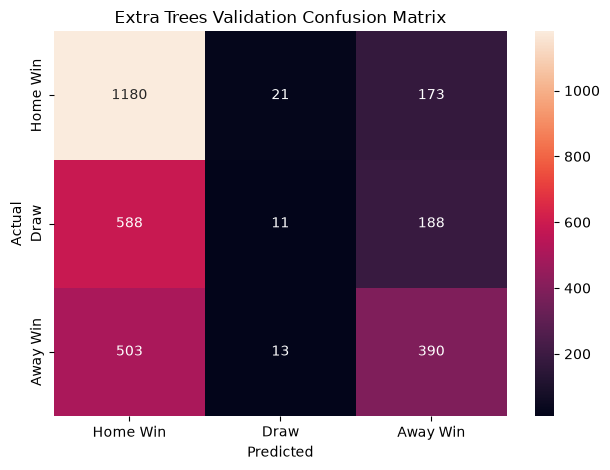

In [24]:
cm_extra = confusion_matrix(
    y_val,
    extra_predictions,
    labels=[
        "Home Win",
        "Draw",
        "Away Win"
    ]
)

sns.heatmap(
    cm_extra,
    annot=True,
    fmt="d",
    xticklabels=[
        "Home Win",
        "Draw",
        "Away Win"
    ],
    yticklabels=[
        "Home Win",
        "Draw",
        "Away Win"
    ]
)

plt.title("Extra Trees Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

### Extra Trees finding

Extra Trees achieved approximately 51.5% validation accuracy, but its
Macro F1 score was only about 0.382.

The confusion matrix shows that the model almost completely failed to
identify Draw matches. Only 11 of 787 Draw matches were correctly
classified.

This demonstrates why Accuracy alone is not suitable for this problem.
A model can achieve reasonable overall accuracy by predicting the more
common Home Win class while performing very poorly on Draws.

Therefore, Extra Trees is not currently competitive with the balanced
Gradient Boosting model.

In [ ]:
%pip install -q xgboost
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
print(label_encoder.classes_)


ModuleNotFoundError: No module named 'xgboost'